<a href="https://colab.research.google.com/github/abrarjahinzihan/Movie_Recommendation_System/blob/main/Movie_Recommendation_System.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Movie Recommendation System
**Project:** Suggest personalized movies using user rating matrices, genre tags, plot summaries and cosine similarity.

**Requirements covered**
1. Load and clean the data (TMDB metadata + MovieLens ratings + links)
2. Exploratory data analysis
3. Content-based filtering (plot overview, tagline, genres, keywords, director, cast + TF-IDF + cosine similarity)
4. Collaborative filtering (user–item rating matrix + item–item cosine similarity)
5. Hybrid recommender (combines both)
6. Evaluation (RMSE for rating prediction, Precision@K / Recall@K for top-N lists, vs. baselines)
7. Personalized recommendations and "movies like X" demo

**Setup:** Upload `movie.zip` to the Colab session (Files panel on the left, drag and drop). Then run all cells.

DATAset link- https://www.kaggle.com/datasets/rounakbanik/the-movies-dataset?utm_source=chatgpt.com



In [2]:
# ===== UPLOAD ZIP CELL =====
import os, zipfile
from google.colab import files

DATA_DIR = "movie_data"

if not os.path.isdir(DATA_DIR):
    print("Click 'Choose Files' and select movie.zip")
    uploaded = files.upload()                      # opens the file picker
    zip_name = next(iter(uploaded))                # name of the uploaded file
    print(f"Extracting {zip_name} ...")
    with zipfile.ZipFile(zip_name) as z:
        z.extractall(DATA_DIR)
    print("Done.")
else:
    print("Data already extracted.")

print(sorted(os.listdir(DATA_DIR)))

Click 'Choose Files' and select movie.zip


Saving movie.zip to movie.zip
Extracting movie.zip ...
Done.
['credits.csv', 'keywords.csv', 'links.csv', 'links_small.csv', 'movies_metadata.csv', 'ratings.csv', 'ratings_small.csv']


In [3]:
import os, zipfile, ast, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import train_test_split
from scipy.sparse import csr_matrix

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.width", 120)
sns.set_style("whitegrid")
np.random.seed(42)

ZIP_PATH = "movie.zip"          # uploaded to the Colab session
DATA_DIR = "movie_data"         # extraction folder
USE_FULL_RATINGS = False        # False = ratings_small (100k, fast)  |  True = ratings.csv (26M, needs High-RAM runtime)

if not os.path.isdir(DATA_DIR):
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(DATA_DIR)
print(sorted(os.listdir(DATA_DIR)))

['credits.csv', 'keywords.csv', 'links.csv', 'links_small.csv', 'movies_metadata.csv', 'ratings.csv', 'ratings_small.csv']


## 1. Load and clean the data

In [4]:
def safe_literal(s):
    """Parse the stringified Python lists/dicts used in the TMDB CSVs."""
    if not isinstance(s, str):
        return []
    try:
        return ast.literal_eval(s)
    except (ValueError, SyntaxError):
        return []

# --- movie metadata (TMDB) ---
movies = pd.read_csv(f"{DATA_DIR}/movies_metadata.csv", low_memory=False)
movies["id"] = pd.to_numeric(movies["id"], errors="coerce")     # a few rows are corrupted (e.g. a date in the id column)
movies = movies.dropna(subset=["id"]).astype({"id": int}).drop_duplicates(subset="id")

# --- ID mapping: MovieLens movieId <-> TMDB id ---
links = pd.read_csv(f"{DATA_DIR}/links_small.csv").dropna(subset=["tmdbId"])
links["tmdbId"] = links["tmdbId"].astype(int)

# --- keywords and credits (TMDB) ---
keywords = pd.read_csv(f"{DATA_DIR}/keywords.csv")
keywords["id"] = pd.to_numeric(keywords["id"], errors="coerce")
keywords = keywords.dropna(subset=["id"]).astype({"id": int}).drop_duplicates(subset="id")

credits = pd.read_csv(f"{DATA_DIR}/credits.csv")
credits["id"] = pd.to_numeric(credits["id"], errors="coerce")
credits = credits.dropna(subset=["id"]).astype({"id": int}).drop_duplicates(subset="id")

# --- user ratings (MovieLens) ---
ratings = pd.read_csv(f"{DATA_DIR}/ratings.csv" if USE_FULL_RATINGS else f"{DATA_DIR}/ratings_small.csv")

print("Metadata rows:", len(movies), "| Links:", len(links), "| Ratings:", len(ratings))
print("Users:", ratings.userId.nunique(), "| Rated movies:", ratings.movieId.nunique())

Metadata rows: 45433 | Links: 9112 | Ratings: 100004
Users: 671 | Rated movies: 9066


In [5]:
# Join movie metadata to MovieLens ids (only movies that appear in links_small)
catalog = links.merge(movies, left_on="tmdbId", right_on="id", how="inner")

catalog["genres_list"] = catalog["genres"].apply(lambda s: [g["name"] for g in safe_literal(s)])
catalog["year"] = pd.to_datetime(catalog["release_date"], errors="coerce").dt.year
catalog["overview"] = catalog["overview"].fillna("")
catalog["tagline"] = catalog["tagline"].fillna("")
for col in ["vote_average", "vote_count", "runtime", "popularity"]:
    catalog[col] = pd.to_numeric(catalog[col], errors="coerce")
catalog = catalog.dropna(subset=["title"]).drop_duplicates(subset="movieId").reset_index(drop=True)

# Keywords as a space-separated string (spaces removed inside a name so "boy next door" -> one token)
kw_map = keywords.set_index("id")["keywords"].apply(
    lambda s: " ".join(d["name"].replace(" ", "") for d in safe_literal(s)))
catalog["keywords_text"] = catalog["tmdbId"].map(kw_map).fillna("")

# Director and top-3 cast from credits
credits_small = credits[credits["id"].isin(catalog["tmdbId"])].set_index("id")
def get_director(crew_str):
    for c in safe_literal(crew_str):
        if c.get("job") == "Director":
            return c["name"].replace(" ", "")
    return ""
def get_cast(cast_str, n=3):
    return " ".join(c["name"].replace(" ", "") for c in safe_literal(cast_str)[:n])

catalog["director"] = catalog["tmdbId"].map(credits_small["crew"].apply(get_director)).fillna("")
catalog["cast_text"] = catalog["tmdbId"].map(credits_small["cast"].apply(get_cast)).fillna("")

print("Catalog size:", len(catalog))
catalog[["movieId", "title", "year", "genres_list", "vote_average"]].head()

Catalog size: 9082


,movieId,title,year,genres_list,vote_average
0,1,Toy Story,1995,"[Animation, Comedy, Family]",7.7
1,2,Jumanji,1995,"[Adventure, Fantasy, Family]",6.9
2,3,Grumpier Old Men,1995,"[Romance, Comedy]",6.5
3,4,Waiting to Exhale,1995,"[Comedy, Drama, Romance]",6.1
4,5,Father of the Bride Part II,1995,[Comedy],5.7


## 2. Exploratory Data Analysis

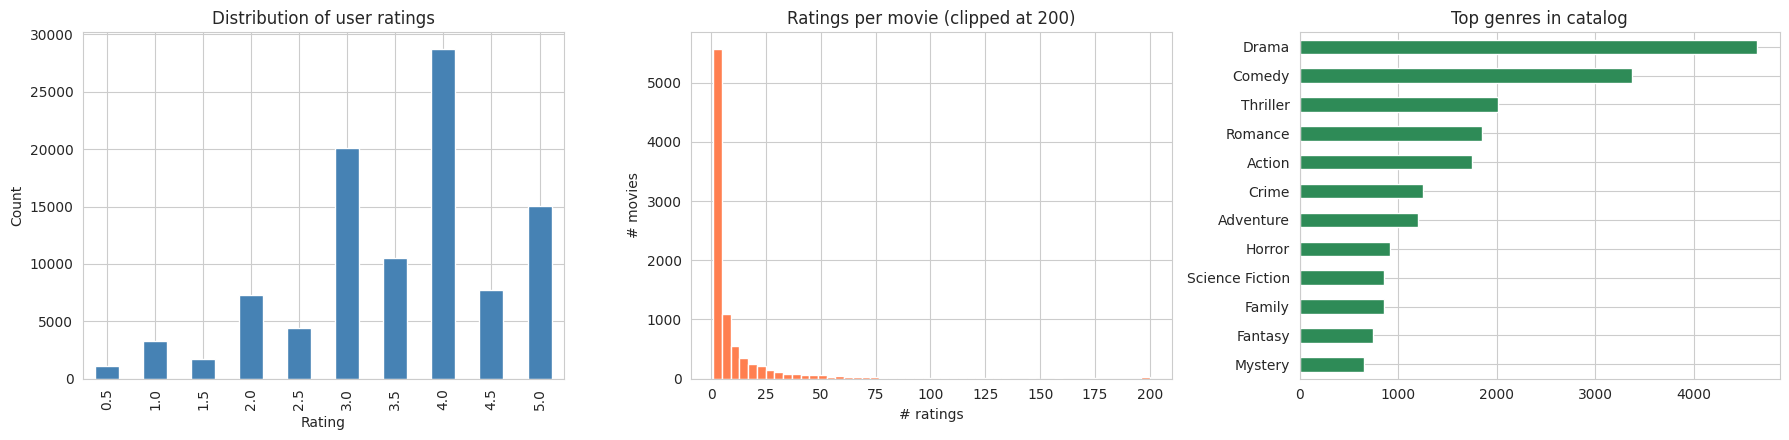

Sparsity of the user-item matrix: 98.36%
Average rating: 3.54


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

ratings["rating"].value_counts().sort_index().plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set_title("Distribution of user ratings")
axes[0].set_xlabel("Rating"); axes[0].set_ylabel("Count")

ratings.groupby("movieId").size().clip(upper=200).hist(bins=50, ax=axes[1], color="coral")
axes[1].set_title("Ratings per movie (clipped at 200)")
axes[1].set_xlabel("# ratings"); axes[1].set_ylabel("# movies")

genre_counts = pd.Series([g for gl in catalog["genres_list"] for g in gl]).value_counts().head(12)
genre_counts.sort_values().plot(kind="barh", ax=axes[2], color="seagreen")
axes[2].set_title("Top genres in catalog")

plt.tight_layout(); plt.show()

n_u, n_i = ratings.userId.nunique(), ratings.movieId.nunique()
print(f"Sparsity of the user-item matrix: {1 - len(ratings)/(n_u*n_i):.2%}")
print(f"Average rating: {ratings.rating.mean():.2f}")

## 3. Shared item universe

Collaborative filtering needs users with enough ratings, and both models must index movies the same way.
So we keep movies and users with enough activity, and use one ordering for both the rating matrix and the TF-IDF matrix.

In [7]:
MIN_USER_RATINGS = 20
MIN_ITEM_RATINGS = 5

r = ratings[ratings["movieId"].isin(catalog["movieId"])].copy()
for _ in range(2):  # iterate twice so both filters hold after each other's removal
    r = r[r.groupby("movieId")["userId"].transform("size") >= MIN_ITEM_RATINGS]
    r = r[r.groupby("userId")["movieId"].transform("size") >= MIN_USER_RATINGS]

catalog = catalog[catalog["movieId"].isin(r["movieId"])].reset_index(drop=True)

user_index = {u: i for i, u in enumerate(sorted(r["userId"].unique()))}
item_index = {m: i for i, m in enumerate(catalog["movieId"])}   # item row == catalog row
movie_to_title = dict(zip(catalog["movieId"], catalog["title"]))
n_users, n_items = len(user_index), len(item_index)
print(f"Users: {n_users} | Items: {n_items} | Ratings kept: {len(r):,}")

Users: 657 | Items: 3482 | Ratings kept: 89,658


## 4. Content-Based Filtering (plot, genres, keywords, cast, director → TF-IDF + cosine similarity)

In [8]:
catalog["soup"] = (
    catalog["overview"] + " " + catalog["tagline"] + " " +
    catalog["genres_list"].apply(lambda g: " ".join(x.replace(" ", "") for x in g)) + " " +
    catalog["keywords_text"] + " " + catalog["director"] + " " + catalog["cast_text"]
)

tfidf = TfidfVectorizer(stop_words="english", min_df=2, max_features=20000, ngram_range=(1, 2))
tfidf_matrix = tfidf.fit_transform(catalog["soup"])
print("TF-IDF matrix:", tfidf_matrix.shape)

title_to_row = pd.Series(catalog.index, index=catalog["title"].str.lower()).groupby(level=0).first()

def similar_movies(title, top_n=10):
    """Movies whose content (plot + genres + keywords + cast/crew) is closest by cosine similarity."""
    key = title.lower()
    if key not in title_to_row.index:
        raise ValueError(f"'{title}' not found in catalog")
    row = int(title_to_row[key])
    sims = cosine_similarity(tfidf_matrix[row], tfidf_matrix).ravel()
    sims[row] = -1                                  # exclude the movie itself
    top = np.argsort(sims)[::-1][:top_n]
    out = catalog.iloc[top][["title", "genres_list", "year", "vote_average"]].copy()
    out["similarity"] = sims[top].round(3)
    return out.reset_index(drop=True)

similar_movies("Toy Story")

TF-IDF matrix: (3482, 20000)


,title,genres_list,year,vote_average,similarity
0,Toy Story 2,"[Animation, Comedy, Family]",1999,7.3,0.450
1,Toy Story 3,"[Animation, Family, Comedy]",2010,7.6,0.439
2,The 40 Year Old Virgin,"[Comedy, Romance]",2005,6.2,0.241
3,Man on the Moon,"[Comedy, Drama, Romance]",1999,6.9,0.140
4,Rebel Without a Cause,[Drama],1955,7.6,0.122
5,Condorman,"[Comedy, Action, Adventure]",1981,5.6,0.108
6,For Love or Money,"[Comedy, Romance]",1993,5.7,0.091
7,Malice,"[Drama, Crime]",1993,5.9,0.083
8,"Monsters, Inc.","[Animation, Comedy, Family]",2001,7.5,0.076
9,Small Soldiers,"[Comedy, Adventure, Fantasy, Science Fiction, Action]",1998,6.2,0.073


## 5. Collaborative Filtering (user–item rating matrix + item–item cosine similarity)

In [9]:
def build_rating_matrix(df):
    """Sparse users x items matrix of raw ratings."""
    u = df["userId"].map(user_index).values
    i = df["movieId"].map(item_index).values
    return csr_matrix((df["rating"].values, (u, i)), shape=(n_users, n_items))

def center_items(R):
    """Item vectors (items x users) with each user's ratings centered on that user's mean (adjusted cosine)."""
    C = R.tocsr(copy=True)
    mu = np.zeros(C.shape[0])
    for u in range(C.shape[0]):
        s, e = C.indptr[u], C.indptr[u + 1]
        if e > s:
            mu[u] = C.data[s:e].mean()
    rows = np.repeat(np.arange(C.shape[0]), np.diff(C.indptr))
    C.data = C.data - mu[rows]
    return C.T.tocsr()

R_full = build_rating_matrix(r)
Xi_full = center_items(R_full)      # items x users, mean-centered
print("Rating matrix:", R_full.shape, "| nnz:", R_full.nnz)

SHRINK = 1.0   # damping so items with very little overlap don't get extreme scores
MIN_CANDIDATE_RATINGS = 20   # only recommend movies with enough ratings to trust the score

def predict_pair(R, Xi, u, i):
    """Predict user u's rating of item i: user mean + similarity-weighted deviation from the user's other ratings."""
    row = R.getrow(u)
    mu = row.data.mean() if row.nnz else 3.5
    js, rs = row.indices, row.data
    keep = js != i
    js, rs = js[keep], rs[keep]
    if len(js) == 0 or Xi[i].nnz == 0:
        return mu
    sims = cosine_similarity(Xi[i], Xi[js]).ravel()
    pos = sims > 0
    if not pos.any():
        return mu
    dev = rs[pos] - mu
    return float(np.clip(mu + np.dot(sims[pos], dev) / (sims[pos].sum() + SHRINK), 0.5, 5.0))

Rating matrix: (657, 3482) | nnz: 89658


In [11]:
def cf_scores_for_user(R, Xi, u):
    """Score every item for user u using the user's centered ratings and item-item similarity."""
    row = R.getrow(u)
    H = row.indices
    if len(H) == 0:
        return np.zeros(Xi.shape[0])
    mu = row.data.mean()
    dev = row.data - mu
    S = np.clip(cosine_similarity(Xi[H], Xi), 0, None)      # |history| x |items|
    num = S.T @ dev
    den = S.sum(axis=0)
    return mu + num / (den + SHRINK)

## 6. Hybrid recommender (content-based user profile + collaborative scores)

In [12]:
def content_scores_for_user(R, u, liked_threshold=4.0):
    """Build a taste profile from the movies the user liked and rank all movies by cosine similarity to it."""
    row = R.getrow(u)
    liked = row.indices[row.data >= liked_threshold]
    if len(liked) == 0:
        liked = row.indices
    profile = np.asarray(tfidf_matrix[liked].mean(axis=0))
    return cosine_similarity(profile, tfidf_matrix).ravel()

def minmax(x):
    lo, hi = x.min(), x.max()
    return (x - lo) / (hi - lo) if hi > lo else np.zeros_like(x)

def recommend(user_id, R, Xi, method="hybrid", n=10, alpha=0.7):
    """Top-n unseen movies for a user. method: 'cf', 'content' or 'hybrid' (alpha = weight on CF)."""
    u = user_index[user_id]
    seen = R.getrow(u).indices
    cf = cf_scores_for_user(R, Xi, u)
    cb = content_scores_for_user(R, u)
    if method == "cf":
        score = cf
    elif method == "content":
        score = cb
    else:
        score = alpha * minmax(cf) + (1 - alpha) * minmax(cb)
    score = score.copy()
    score[seen] = -np.inf
    score[np.diff(Xi.indptr) < MIN_CANDIDATE_RATINGS] = -np.inf
    top = np.argsort(score)[::-1][:n]
    out = catalog.iloc[top][["title", "genres_list", "year", "vote_average"]].copy()
    out["score"] = score[top].round(3)
    return out.reset_index(drop=True)

recommend(1, R_full, Xi_full, method="hybrid", n=10)

,title,genres_list,year,vote_average,score
0,The Birds,[Horror],1963,7.3,0.567
1,Annie Hall,"[Comedy, Drama, Romance]",1977,7.8,0.560
2,A Room with a View,"[Drama, Romance]",1985,6.9,0.551
3,Doctor Zhivago,"[Drama, Romance, War]",1965,7.4,0.549
4,In the Heat of the Night,"[Crime, Drama, Mystery, Thriller]",1967,7.5,0.537
5,Notorious,"[Thriller, Drama, Romance]",1946,7.8,0.537
6,A Hard Day's Night,"[Comedy, Music]",1964,7.3,0.531
7,The Purple Rose of Cairo,"[Fantasy, Comedy, Romance]",1985,7.3,0.527
8,Dr. No,"[Adventure, Action, Thriller]",1962,6.9,0.527
9,Drugstore Cowboy,"[Crime, Drama]",1989,7.0,0.526


## 7. Evaluation

**Rating prediction (RMSE):** train on 80% of ratings, predict the held-out 20%.
**Top-N ranking (Precision@10, Recall@10):** for sampled users, recommend 10 unseen movies and check how many held-out movies rated ≥ 4 appear.

In [13]:
train, test = train_test_split(r, test_size=0.2, random_state=42)
R_train = build_rating_matrix(train)
Xi_train = center_items(R_train)
global_mean = train["rating"].mean()

# --- RMSE on a sample of test ratings ---
sample = test.sample(min(2000, len(test)), random_state=1)
preds, truth, user_mean_preds = [], [], []
for _, row in sample.iterrows():
    u, i = user_index[row.userId], item_index[row.movieId]
    user_row = R_train.getrow(u)
    um = user_row.data.mean() if user_row.nnz else global_mean
    preds.append(predict_pair(R_train, Xi_train, u, i))
    user_mean_preds.append(um)
    truth.append(row.rating)

rmse = lambda p: np.sqrt(np.mean((np.array(p) - np.array(truth)) ** 2))
print(f"RMSE  global-mean baseline : {np.sqrt(np.mean((global_mean - np.array(truth))**2)):.3f}")
print(f"RMSE  user-mean baseline   : {rmse(user_mean_preds):.3f}")
print(f"RMSE  item-based CF        : {rmse(preds):.3f}")

RMSE  global-mean baseline : 1.043
RMSE  user-mean baseline   : 0.960
RMSE  item-based CF        : 0.885


            Precision@10  Recall@10
popularity        0.1255     0.1086
cf                0.0775     0.0542
content           0.0630     0.0638
hybrid            0.1030     0.0880


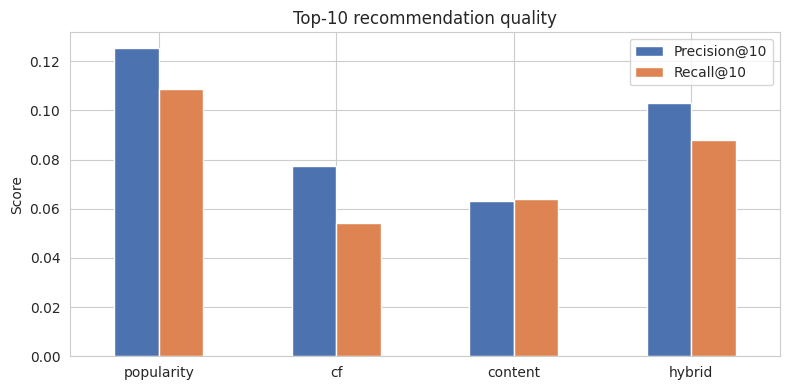

In [14]:
def recommend_ids(uid, R, Xi, method, n, alpha=0.7):
    u = user_index[uid]
    seen = R.getrow(u).indices
    cf = cf_scores_for_user(R, Xi, u)
    cb = content_scores_for_user(R, u)
    score = {"cf": cf, "content": cb}.get(method, alpha * minmax(cf) + (1 - alpha) * minmax(cb)).copy()
    score[seen] = -np.inf
    score[np.diff(Xi.indptr) < MIN_CANDIDATE_RATINGS] = -np.inf
    return catalog["movieId"].values[np.argsort(score)[::-1][:n]]

def evaluate_ids(method, k=10, n_users_eval=200):
    rel = test[test["rating"] >= 4].groupby("userId")["movieId"].apply(set)
    users = [u for u in rel.index if u in user_index]
    users = pd.Series(users).sample(min(n_users_eval, len(users)), random_state=7).tolist()
    pop_rank = train["movieId"].value_counts().index.tolist()
    p, rc = [], []
    for uid in users:
        if method == "popularity":
            seen = set(train.loc[train.userId == uid, "movieId"])
            recs = [m for m in pop_rank if m not in seen][:k]
        else:
            recs = recommend_ids(uid, R_train, Xi_train, method, k)
        hits = len(set(recs) & rel[uid])
        p.append(hits / k); rc.append(hits / len(rel[uid]))
    return np.mean(p), np.mean(rc)

scores = {m: evaluate_ids(m) for m in ["popularity", "cf", "content", "hybrid"]}
res = pd.DataFrame(scores, index=["Precision@10", "Recall@10"]).T
print(res.round(4))

res.plot(kind="bar", figsize=(8, 4), color=["#4C72B0", "#DD8452"], rot=0)
plt.title("Top-10 recommendation quality"); plt.ylabel("Score"); plt.tight_layout(); plt.show()

## 8. Get recommendations

In [15]:
# Personalized picks for a user (trained on all ratings)
print("Top picks for user 1 (hybrid):")
display(recommend(1, R_full, Xi_full, method="hybrid", n=10))

# Movies similar to a title you like (content-based)
print("Movies like 'The Dark Knight' (content-based):")
display(similar_movies("The Dark Knight", top_n=10))

Top picks for user 1 (hybrid):


,title,genres_list,year,vote_average,score
0,The Birds,[Horror],1963,7.3,0.567
1,Annie Hall,"[Comedy, Drama, Romance]",1977,7.8,0.560
2,A Room with a View,"[Drama, Romance]",1985,6.9,0.551
3,Doctor Zhivago,"[Drama, Romance, War]",1965,7.4,0.549
4,In the Heat of the Night,"[Crime, Drama, Mystery, Thriller]",1967,7.5,0.537
5,Notorious,"[Thriller, Drama, Romance]",1946,7.8,0.537
6,A Hard Day's Night,"[Comedy, Music]",1964,7.3,0.531
7,The Purple Rose of Cairo,"[Fantasy, Comedy, Romance]",1985,7.3,0.527
8,Dr. No,"[Adventure, Action, Thriller]",1962,6.9,0.527
9,Drugstore Cowboy,"[Crime, Drama]",1989,7.0,0.526


Movies like 'The Dark Knight' (content-based):


,title,genres_list,year,vote_average,similarity
0,The Dark Knight Rises,"[Action, Crime, Drama, Thriller]",2012,7.6,0.430
1,Batman Begins,"[Action, Crime, Drama]",2005,7.5,0.323
2,Batman Returns,"[Action, Fantasy]",1992,6.6,0.287
3,Batman Forever,"[Action, Crime, Fantasy]",1995,5.2,0.267
4,Batman,"[Fantasy, Action]",1989,7.0,0.191
5,Batman: Mask of the Phantasm,"[Action, Adventure, Animation, Family]",1993,7.4,0.160
6,Batman v Superman: Dawn of Justice,"[Action, Adventure, Fantasy]",2016,5.7,0.158
7,Batman & Robin,"[Action, Crime, Fantasy]",1997,4.2,0.135
8,"Batman: The Dark Knight Returns, Part 1","[Action, Animation]",2012,7.7,0.129
9,Sherlock Holmes: A Game of Shadows,"[Adventure, Action, Crime, Mystery]",2011,7.0,0.119


## 9. Conclusions

- **Rating prediction:** item-based collaborative filtering (mean-centered, cosine similarity) gives the lowest RMSE, beating the user-mean and global-mean baselines.
- **Top-10 recommendations:** on this sample (100k ratings, 657 users), the hybrid model beats collaborative filtering and content-based filtering alone, but a simple popularity baseline still scores higher. Personalization needs more ratings per user to outperform popularity reliably, so the full `ratings.csv` should help.
- **Content-based filtering** works for movies nobody has rated yet (new items), and it finds movies that share plot, genre, cast and keywords. Its suggestions can be too close to the seed movie.
- **Collaborative filtering** finds what similar users enjoy, but it is weak for new users and for movies with few ratings (handled here by a minimum-rating filter).
- **Next steps:** matrix factorization (SVD / ALS), tuning `alpha`, `SHRINK` and `MIN_CANDIDATE_RATINGS`, and running with `USE_FULL_RATINGS = True`.